In [1]:
!pip install mysql-connector-python pandas matplotlib seaborn

In [2]:
import mysql.connector
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
sns.set_theme(style="whitegrid")

In [4]:
# Establish DB-API connection
conn = mysql.connector.connect(
    host="localhost",
    user="root",
    password="Mujhtaba1",
    database="propfind"
)

if conn.is_connected():
    print("Connected to MySQL successfully!")

Connected to MySQL successfully!


In [5]:
# Helper function to run any SQL query via DB-API and return a DataFrame
def fetch_df(query):
    cursor = conn.cursor(dictionary=True)
    cursor.execute(query)
    df = pd.DataFrame(cursor.fetchall())
    cursor.close()
    return df

C:\Users\HASSAAN\AppData\Local\Temp\ipykernel_2340\2894994036.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_cities, x="Average_Property_Price_sqft", y="City_Name", palette="viridis")


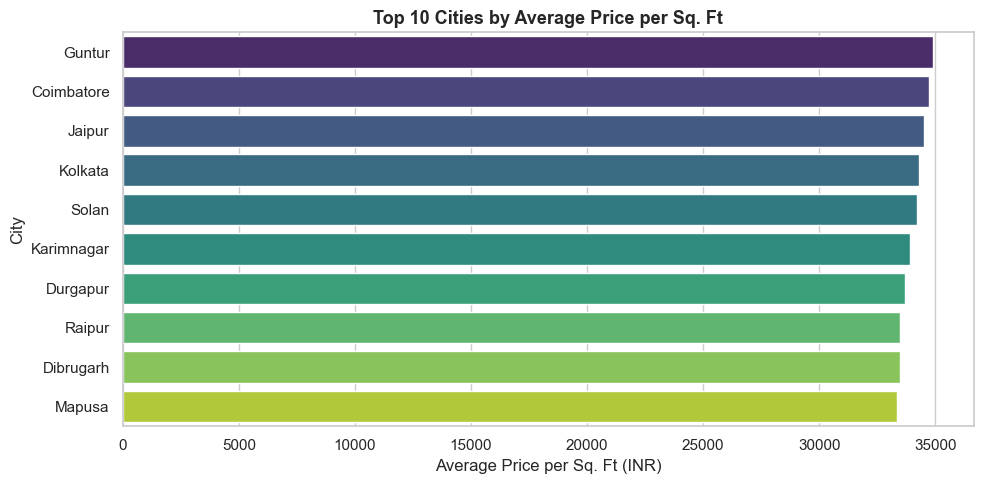

In [6]:
df_cities = fetch_df("""
    SELECT City_Name, Average_Property_Price_sqft
    FROM cities
    ORDER BY Average_Property_Price_sqft DESC
    LIMIT 10;
""")

plt.figure(figsize=(10, 5))
sns.barplot(data=df_cities, x="Average_Property_Price_sqft", y="City_Name", palette="viridis")
plt.title("Top 10 Cities by Average Price per Sq. Ft", fontsize=13, fontweight="bold")
plt.xlabel("Average Price per Sq. Ft (INR)")
plt.ylabel("City")
plt.tight_layout()
plt.show()

C:\Users\HASSAAN\AppData\Local\Temp\ipykernel_2340\4127112834.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_types, x="Property_Type", y="avg_price_sqft", palette="mako")


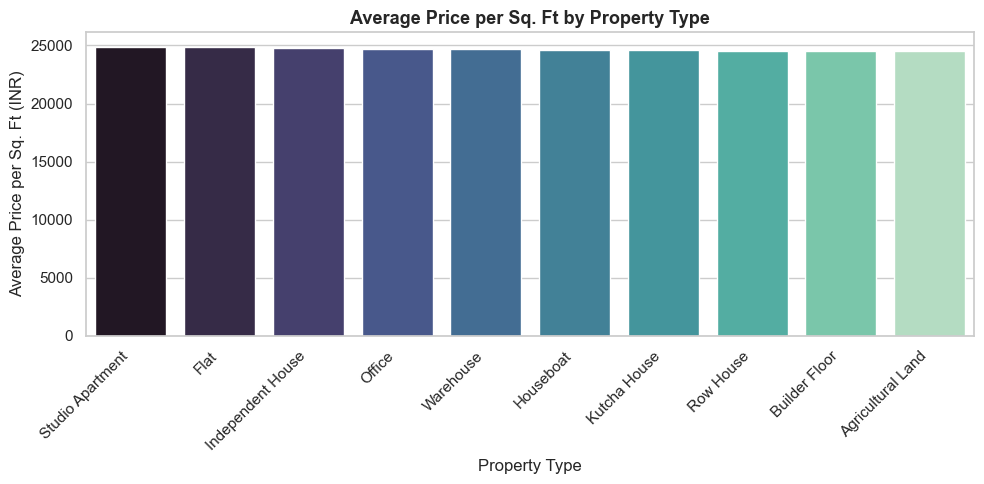

In [7]:
df_types = fetch_df("""
    SELECT Property_Type, ROUND(AVG(price_per_sqft), 2) AS avg_price_sqft
    FROM properties
    GROUP BY Property_Type
    ORDER BY avg_price_sqft DESC
    LIMIT 10;
""")

plt.figure(figsize=(10, 5))
sns.barplot(data=df_types, x="Property_Type", y="avg_price_sqft", palette="mako")
plt.title("Average Price per Sq. Ft by Property Type", fontsize=13, fontweight="bold")
plt.xlabel("Property Type")
plt.ylabel("Average Price per Sq. Ft (INR)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

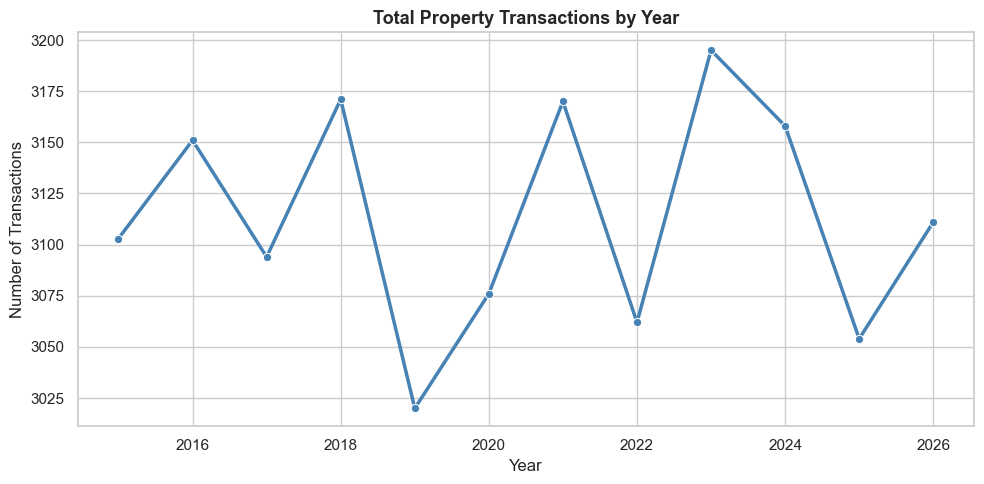

In [8]:
df_yearly = fetch_df("""
    SELECT YEAR(Transaction_Date) AS sale_year, COUNT(Transaction_ID) AS total_sales
    FROM property_transactions
    WHERE Transaction_Date IS NOT NULL
    GROUP BY YEAR(Transaction_Date)
    ORDER BY sale_year ASC;
""")

plt.figure(figsize=(10, 5))
sns.lineplot(data=df_yearly, x="sale_year", y="total_sales", marker="o", linewidth=2.5, color="steelblue")
plt.title("Total Property Transactions by Year", fontsize=13, fontweight="bold")
plt.xlabel("Year")
plt.ylabel("Number of Transactions")
plt.tight_layout()
plt.show()

C:\Users\HASSAAN\AppData\Local\Temp\ipykernel_2340\847499349.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_tier, x="Tier", y="Average_Property_Price_sqft", palette="Set2")


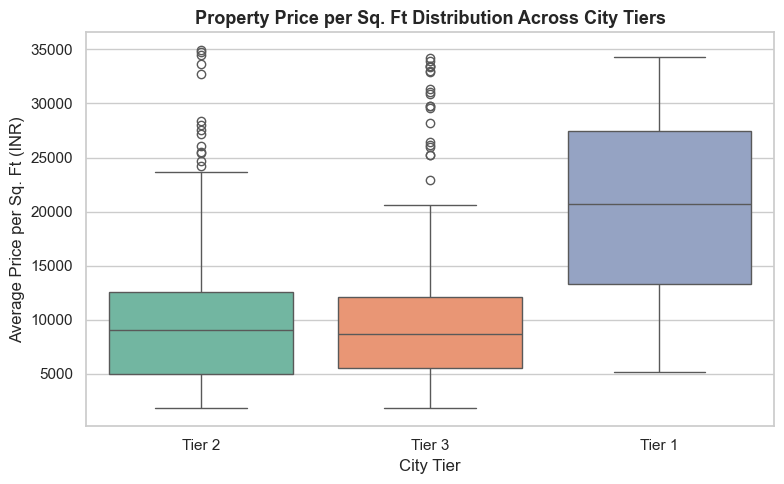

In [9]:
df_tier = fetch_df("""
    SELECT Tier, Average_Property_Price_sqft
    FROM cities
    WHERE Tier IS NOT NULL;
""")

plt.figure(figsize=(8, 5))
sns.boxplot(data=df_tier, x="Tier", y="Average_Property_Price_sqft", palette="Set2")
plt.title("Property Price per Sq. Ft Distribution Across City Tiers", fontsize=13, fontweight="bold")
plt.xlabel("City Tier")
plt.ylabel("Average Price per Sq. Ft (INR)")
plt.tight_layout()
plt.show()

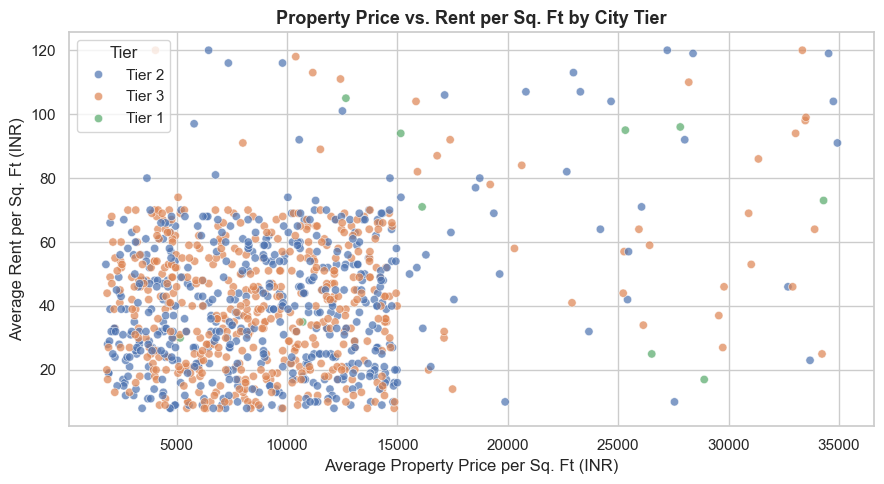

In [10]:
df_rent = fetch_df("""
    SELECT City_Name, Tier, Average_Property_Price_sqft, Average_Rent_sqft
    FROM cities
    WHERE Average_Property_Price_sqft > 0 AND Average_Rent_sqft > 0;
""")

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=df_rent,
    x="Average_Property_Price_sqft",
    y="Average_Rent_sqft",
    hue="Tier",
    alpha=0.7
)
plt.title("Property Price vs. Rent per Sq. Ft by City Tier", fontsize=13, fontweight="bold")
plt.xlabel("Average Property Price per Sq. Ft (INR)")
plt.ylabel("Average Rent per Sq. Ft (INR)")
plt.tight_layout()
plt.show()

In [11]:
conn.close()